# Customer Churn Analytics

**Goal:** understand why customers leave a telecom provider and build a model that flags at-risk customers.

**Workflow:** load data → clean → exploratory analysis → feature engineering → modeling → evaluation → business recommendations.

> The dataset is synthetic and generated by `src/generate_data.py`, so the project is fully reproducible.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

def find_project_root():
    """Walk up from the current folder until the project's src/generate_data.py is found."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "src" / "generate_data.py").exists():
            return folder
    raise FileNotFoundError(
        "Project root not found. Start Jupyter from inside the customer-churn-analytics "
        "folder (the one containing src/ and data/), then reopen this notebook."
    )

ROOT = find_project_root()
DATA_PATH = ROOT / "data" / "customer_churn.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load data

In [2]:
if not DATA_PATH.exists():
    sys.path.insert(0, str(ROOT / "src"))
    from generate_data import generate
    DATA_PATH.parent.mkdir(exist_ok=True)
    generate().to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(5025, 13)


,customer_id,tenure_months,contract,internet_service,payment_method,senior_citizen,has_partner,paperless_billing,tech_support,support_calls,monthly_charges,total_charges,churn
0,C100000,13,One year,Fiber,Electronic check,0,1,0,0,0,92.62,1204.16,1
1,C100001,23,Month-to-month,DSL,Electronic check,0,1,0,0,0,63.05,1415.38,0
2,C100002,11,Two year,DSL,Credit card,0,0,0,1,5,57.19,658.76,0
3,C100003,54,One year,Fiber,Credit card,0,0,1,0,1,80.14,4137.22,0
4,C100004,8,Month-to-month,Fiber,Bank transfer,0,1,1,0,2,74.05,617.78,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        5025 non-null   str    
 1   tenure_months      5025 non-null   int64  
 2   contract           5025 non-null   str    
 3   internet_service   5025 non-null   str    
 4   payment_method     5025 non-null   str    
 5   senior_citizen     5025 non-null   int64  
 6   has_partner        5025 non-null   int64  
 7   paperless_billing  5025 non-null   int64  
 8   tech_support       5025 non-null   int64  
 9   support_calls      5025 non-null   int64  
 10  monthly_charges    5025 non-null   float64
 11  total_charges      4975 non-null   float64
 12  churn              5025 non-null   int64  
dtypes: float64(2), int64(7), str(4)
memory usage: 510.5 KB


## 2. Data cleaning

Checks: duplicates, missing values, and data types.

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
print()
print(df.isna().sum()[lambda s: s > 0])

Duplicate rows: 25
Duplicate customer IDs: 25

total_charges    50
dtype: int64


In [5]:
df = df.drop_duplicates(subset="customer_id").reset_index(drop=True)

# Missing total_charges: reconstruct from monthly charges x tenure
missing = df["total_charges"].isna()
df.loc[missing, "total_charges"] = df.loc[missing, "monthly_charges"] * df.loc[missing, "tenure_months"]

assert df.isna().sum().sum() == 0
print("Clean shape:", df.shape)

Clean shape: (5000, 13)


## 3. Exploratory data analysis

In [6]:
churn_rate = df["churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}")
df.describe().T

Overall churn rate: 37.4%


,count,mean,std,min,25%,50%,75%,max
tenure_months,5000.0,30.876800,20.141568,1.00,15.0000,26.000,43.0000,72.00
senior_citizen,5000.0,0.166200,0.372297,0.00,0.0000,0.000,0.0000,1.00
has_partner,5000.0,0.481200,0.499696,0.00,0.0000,0.000,1.0000,1.00
paperless_billing,5000.0,0.590200,0.491846,0.00,0.0000,1.000,1.0000,1.00
tech_support,5000.0,0.321200,0.466984,0.00,0.0000,0.000,1.0000,1.00
support_calls,5000.0,1.225200,1.217531,0.00,0.0000,1.000,2.0000,9.00
monthly_charges,5000.0,64.445388,24.581658,18.00,48.7125,65.625,86.1425,115.94
total_charges,5000.0,2002.367570,1599.922263,18.12,781.4650,1528.770,2821.2350,8335.67
churn,5000.0,0.374400,0.484016,0.00,0.0000,0.000,1.0000,1.00


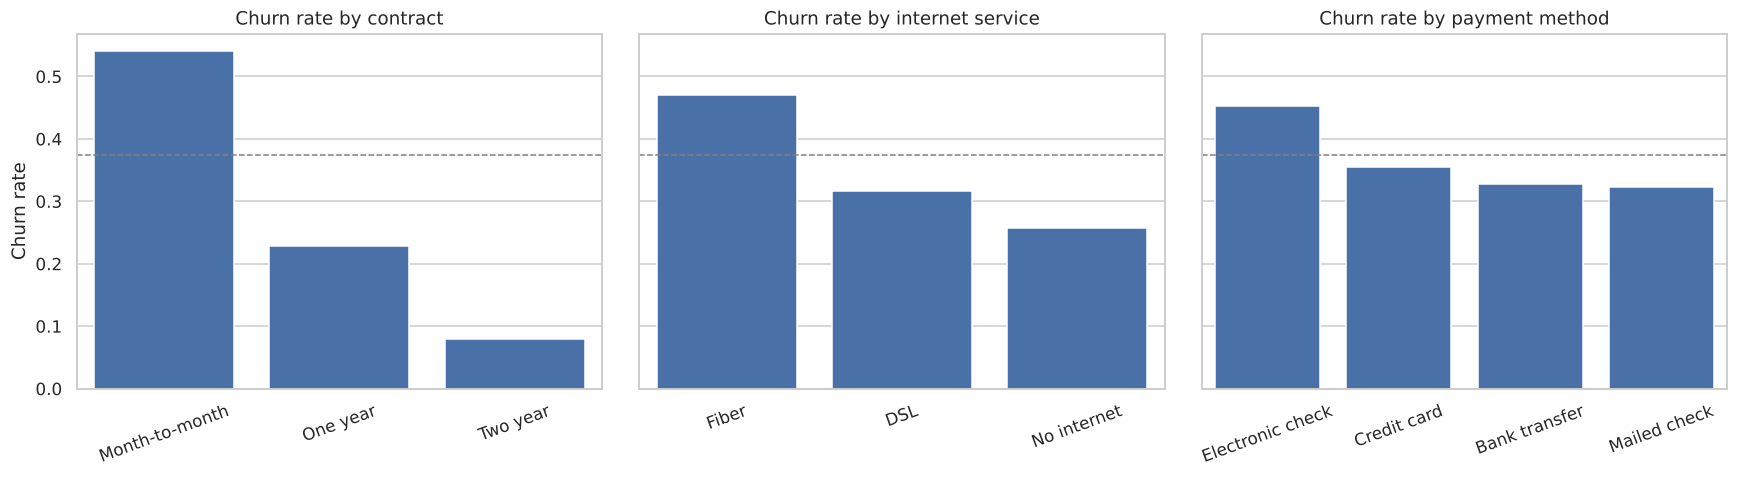

In [7]:
cat_cols = ["contract", "internet_service", "payment_method"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, col in zip(axes, cat_cols):
    rates = df.groupby(col)["churn"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="#3b6fb6")
    ax.axhline(churn_rate, ls="--", color="grey", lw=1)
    ax.set_title(f"Churn rate by {col.replace('_', ' ')}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "churn_by_category.png", dpi=150)
plt.show()

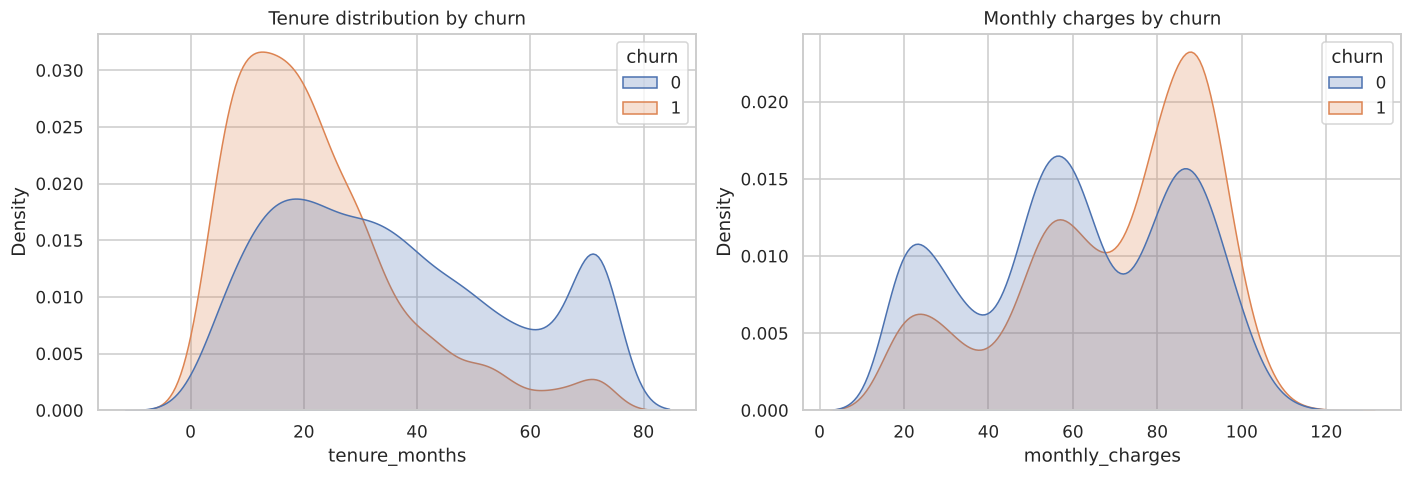

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.kdeplot(data=df, x="tenure_months", hue="churn", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("Tenure distribution by churn")
sns.kdeplot(data=df, x="monthly_charges", hue="churn", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.savefig(FIG_DIR / "tenure_charges_by_churn.png", dpi=150)
plt.show()

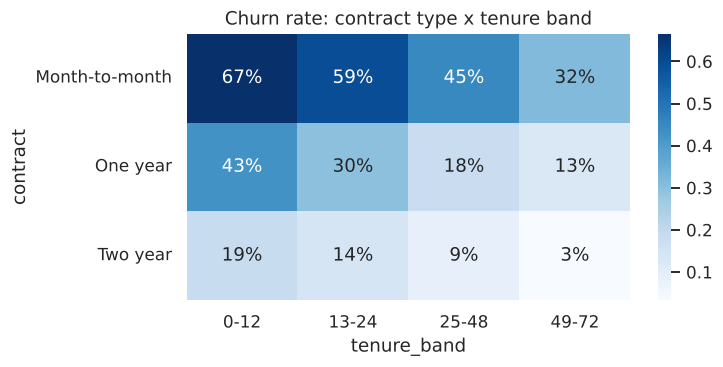

In [9]:
df["tenure_band"] = pd.cut(
    df["tenure_months"], bins=[0, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)
pivot = df.pivot_table(index="contract", columns="tenure_band", values="churn", aggfunc="mean", observed=True)
plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Blues")
plt.title("Churn rate: contract type x tenure band")
plt.tight_layout()
plt.savefig(FIG_DIR / "churn_heatmap.png", dpi=150)
plt.show()

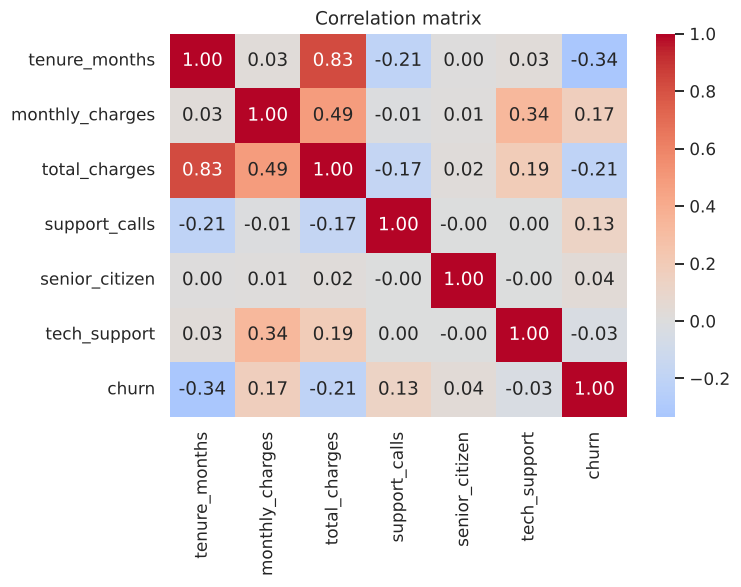

In [10]:
num_cols = ["tenure_months", "monthly_charges", "total_charges", "support_calls", "senior_citizen", "tech_support", "churn"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation.png", dpi=150)
plt.show()

## 4. Feature engineering

In [11]:
df["avg_monthly_spend"] = df["total_charges"] / df["tenure_months"]
df["is_new_customer"] = (df["tenure_months"] <= 12).astype(int)
df["high_support_usage"] = (df["support_calls"] >= 3).astype(int)

target = "churn"
numeric = ["tenure_months", "monthly_charges", "total_charges", "support_calls", "avg_monthly_spend"]
binary = ["senior_citizen", "has_partner", "paperless_billing", "tech_support", "is_new_customer", "high_support_usage"]
categorical = ["contract", "internet_service", "payment_method"]

X = df[numeric + binary + categorical]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(4000, 14) (1000, 14)


## 5. Modeling

Two models are compared: logistic regression (interpretable baseline) and a random forest.

In [12]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", binary),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

pipes, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pipes[name] = pipe
    rows.append({"model": name, "cv_auc_mean": cv_auc.mean(), "cv_auc_std": cv_auc.std(),
                 "test_auc": roc_auc_score(y_test, proba)})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,cv_auc_mean,cv_auc_std,test_auc
model,,,
Logistic Regression,0.802,0.012,0.827
Random Forest,0.790,0.020,0.798


## 6. Evaluation

In [13]:
best_name = results["test_auc"].idxmax()
best = pipes[best_name]
pred = best.predict(X_test)
print(f"Best model: {best_name}\n")
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

Best model: Logistic Regression

              precision    recall  f1-score   support

      Stayed       0.85      0.72      0.78       626
     Churned       0.62      0.79      0.70       374

    accuracy                           0.74      1000
   macro avg       0.74      0.75      0.74      1000
weighted avg       0.76      0.74      0.75      1000



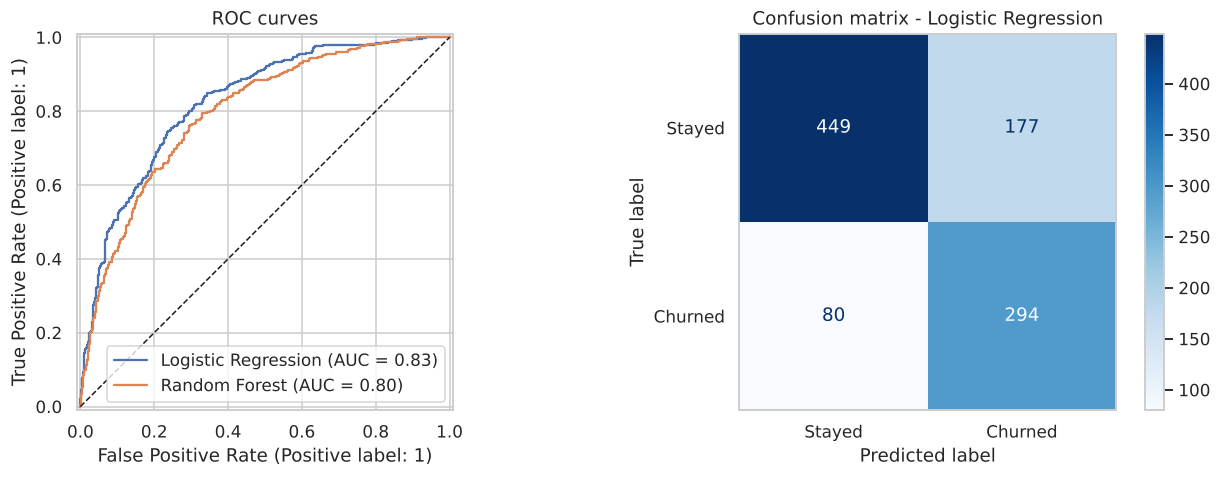

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipe in pipes.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves")
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Stayed", "Churned"], cmap="Blues", ax=axes[1]
)
axes[1].grid(False)
axes[1].set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_evaluation.png", dpi=150)
plt.show()

### Feature importance

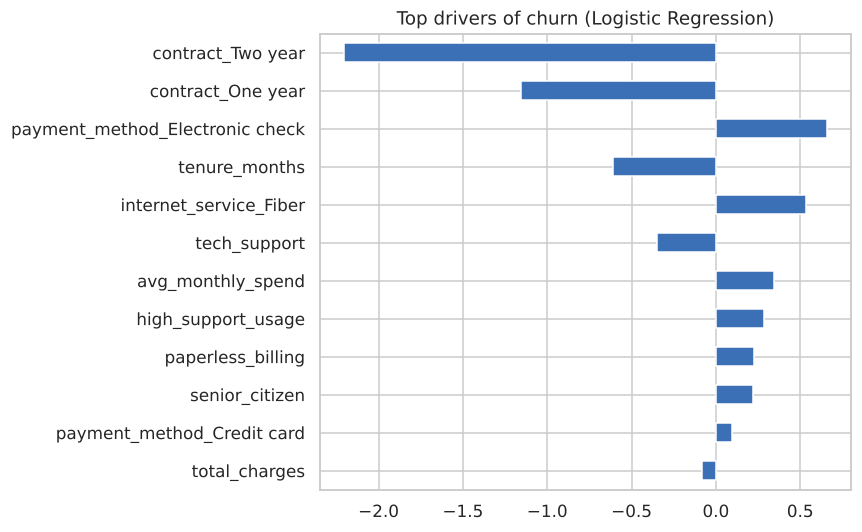

In [15]:
feature_names = best.named_steps["prep"].get_feature_names_out()
clf = best.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    importance = pd.Series(clf.feature_importances_, index=feature_names)
else:
    importance = pd.Series(clf.coef_[0], index=feature_names)
importance.index = importance.index.str.replace(r"^(num|bin|cat)__", "", regex=True)

top = importance.reindex(importance.abs().sort_values(ascending=False).head(12).index)[::-1]
plt.figure(figsize=(8, 5))
top.plot.barh(color="#3b6fb6")
plt.title(f"Top drivers of churn ({best_name})")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150)
plt.show()

## 7. Business application: risk segmentation

In [16]:
scored = X_test.copy()
scored["churn_probability"] = best.predict_proba(X_test)[:, 1]
scored["actual_churn"] = y_test.values
scored["risk_tier"] = pd.cut(
    scored["churn_probability"], bins=[0, 0.3, 0.6, 1.0], labels=["Low", "Medium", "High"], include_lowest=True
)
summary = scored.groupby("risk_tier", observed=True).agg(
    customers=("actual_churn", "size"),
    actual_churn_rate=("actual_churn", "mean"),
    avg_monthly_charges=("monthly_charges", "mean"),
).round(3)
summary

,customers,actual_churn_rate,avg_monthly_charges
risk_tier,,,
Low,349,0.095,56.098
Medium,311,0.350,60.358
High,340,0.682,75.562


In [17]:
high = scored[scored["risk_tier"] == "High"]
at_risk_revenue = (high["monthly_charges"] * 12).sum()
print(f"High-risk customers in test set: {len(high)}")
print(f"Annualized revenue at risk: ${at_risk_revenue:,.0f}")

High-risk customers in test set: 340
Annualized revenue at risk: $308,291


## 8. Key findings & recommendations

Takeaways from this dataset:

1. **Contract type is the strongest lever.** Month-to-month customers churn far more than annual/two-year customers; offer discounts to convert them.
2. **Early tenure is the danger zone.** Churn is concentrated in the first 12 months - invest in onboarding.
3. **Fiber and electronic-check customers** show elevated churn - investigate pricing/quality and push autopay.
4. **Tech support and low support-call volume** are protective - proactively reach out to customers with repeated support calls.
5. **Use the risk tiers** to target retention offers at the High tier first for the best ROI.

**Next steps:** hyperparameter tuning, cost-sensitive threshold selection, SHAP explanations, and A/B testing of retention campaigns.